# ESP32 on-device bird detector v2 (motion ROI → tight box → Pi crop)

This notebook trains the small detector that runs **on the ESP32**, so the Pi only ever receives a letterboxed bird crop instead of the whole scene.

## Pipeline this model is built for

1. **ESP32 motion check** (existing firmware) produces a rough motion box.
2. `square_roi()` turns the motion box into a square region of the full frame (expanded, minimum size, shifted inside the frame; anything still outside is padded with `PAD_VALUE`).
3. The region is resampled to `INPUT_SIZE × INPUT_SIZE` RGB with `reference_sample()` and fed to the int8 detector.
4. The best detection is mapped back to frame pixels, expanded by `PI_CROP_CONTEXT` per edge, cropped from the full-resolution frame and letterboxed to `PI_CROP_SIZE` with `make_pi_crop()`. Only that crop (JPEG) plus a small JSON goes to the Pi.

Every geometric step is defined once here in plain NumPy and written to `esp32_detector_contract.json` / `esp32_detector_contract.h`. The C++ firmware and the Pi-side isBird notebook must reproduce these functions exactly; section 4 checks that the TensorFlow training pipeline matches the NumPy reference.

## Data

`combined_annotations.csv` from `merge_esp32_datasets.py`: tight boxes in each image's own pixel space, `split_group` capture sessions, legacy 160×120 and current 640×480 frames.

- Training regions are **simulated motion ROIs**: bird-centred regions with random slack (motion boxes are never exact), random regions anywhere (mostly negatives), and whole-frame regions.
- Boxes that are tiny, mostly cut off by the region, or too small after resampling become **ignore** areas: they are neither positives nor negatives.
- Splits are by `split_group` (capture session) per source, so burst frames never leak between train / validation / test.

## Model

MobileNetV2 α=0.35 (ImageNet weights) truncated at `block_13_expand_relu` (stride 16 → 8×8 grid at 128 px), a separable-conv head, and two outputs: box `[1, G, G, A·4]` and score logits `[1, G, G, A]`. No reshape/sigmoid/NMS in the graph — decoding is a few lines of C. Full-integer export with uint8 input (raw RGB bytes), int8 outputs.

Run top to bottom. `QUICK_RUN = True` is only a pipeline check.

## 1. Configuration

In [1]:
# ---- Inputs ------------------------------------------------------------------
COMBINED_CSV = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Training Manifest\combined_annotations.csv"
# Searched (recursively, by file name) only when a row's stored image_path does not exist.
IMAGE_ROOTS = [
    r"E:\Datasets\ESP32_capture",
    r"C:\Users\Joe\Pictures\ESP32Cam",
]
OUTPUT_ROOT = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Multi_Object_Detector\runs"

# ---- Splits (by split_group, separately per source_dataset) ------------------
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15
# Sessions bigger than this are cut into time blocks so one long burst session
# cannot become the whole test set (e.g. a single 44-minute session holding half
# of the 640x480 data). Blocks are separated by a dropped buffer to limit leakage.
MAX_SESSION_IMAGES = 250
SESSION_BLOCK_MINUTES = 10
BLOCK_BUFFER_SECONDS = 60

# ---- Detector input / model --------------------------------------------------
INPUT_SIZE = 128            # 96 / 128 / 160. Grid = INPUT_SIZE / 16.
BACKBONE_ALPHA = 0.35
WEIGHTS = "imagenet"        # None trains from scratch.
FEATURE_LAYER = "block_13_expand_relu"   # stride 16
FEATURE_STRIDE = 16
NUM_ANCHORS = 3
HEAD_CHANNELS = 64
PAD_VALUE = 114             # value for pixels outside the frame (ROI and Pi letterbox)

# ---- Motion ROI contract (must match firmware) -------------------------------
ROI_EXPAND = 1.5            # square side = max(motion w, h) * ROI_EXPAND
ROI_MIN_SIDE_FRACTION = 0.25  # ... but at least this fraction of min(frame w, h)

# ---- Simulated motion boxes for training -------------------------------------
SAMPLE_MIX = {"bird_roi": 0.60, "random_roi": 0.30, "whole_frame": 0.10}
RANDOM_ROI_NO_BIRD_SHARE = 0.5     # random_roi draws this share from no_bird images
MOTION_SLACK_MAX = 1.0      # each motion-box edge grows by U(0, this) * bird size
MOTION_SHIFT_STD = 0.25     # motion-box centre shift, in bird sizes
MOTION_UNION_PROB = 0.2     # motion box covers every bird in the frame
RANDOM_ROI_SIZE = (0.05, 0.8)  # log-uniform motion box size, fraction of min(frame w, h)

# ---- Target rules --------------------------------------------------------------
MIN_BOX_PX = 4              # source boxes smaller than this per side become ignore areas
MIN_VISIBLE_FRACTION = 0.6  # less visible than this inside the ROI -> ignore area
MIN_TARGET_PX = 6           # boxes smaller than this after resampling -> ignore area

# ---- Training ------------------------------------------------------------------
BATCH_SIZE = 64
STEPS_PER_EPOCH = 500
HEAD_EPOCHS = 6
FINE_TUNE_EPOCHS = 60
HEAD_LR = 2e-3
FINE_TUNE_LR = 3e-4
EARLY_STOP_PATIENCE = 12    # validation loss is noisy; v1 stopped after 13 epochs
NEIGHBOUR_POSITIVES = True  # also assign each bird to the 2 nearest neighbouring cells
FOCAL_ALPHA = 0.25
FOCAL_GAMMA = 2.0
BOX_LOSS_WEIGHT = 2.0
AUGMENT_COLOR = True
SEED = 1234

# ---- Decode / evaluation --------------------------------------------------------
CANDIDATE_SCORE_THRESHOLD = 0.05
NMS_IOU = 0.45
MAX_DETECTIONS = 5
MAX_FALSE_TRIGGER_RATE = 0.10  # threshold = best crop recall with at most this many empty ROIs firing
THRESHOLD_MODES = ("bird_roi", "random_roi")  # motion-ROI path only; whole_frame is reported, not tuned
CROP_COVERAGE_MIN = 0.9     # a bird is "captured" if this share of its box is inside the Pi crop
IOU_MATCH = 0.5             # reported alongside crop recall

# ---- Pi crop contract -----------------------------------------------------------
PI_CROP_CONTEXT = 0.25      # each edge grows by this fraction of the detected box size
PI_CROP_SIZE = 224

# ---- Export ---------------------------------------------------------------------
REPRESENTATIVE_SAMPLES = 400
TFLITE_EVAL_LIMIT = None    # None = every validation/test ROI

QUICK_RUN = False
if QUICK_RUN:
    STEPS_PER_EPOCH = 10
    HEAD_EPOCHS = 1
    FINE_TUNE_EPOCHS = 1
    EARLY_STOP_PATIENCE = 1
    REPRESENTATIVE_SAMPLES = 20
    TFLITE_EVAL_LIMIT = 120

assert INPUT_SIZE % FEATURE_STRIDE == 0
GRID = INPUT_SIZE // FEATURE_STRIDE
assert abs(sum(SAMPLE_MIX.values()) - 1) < 1e-9

## 2. Environment and helpers

In [2]:
import hashlib
import json
import math
import os
import platform
import random
import re
import time
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath, PureWindowsPath

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

keras = tf.keras

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


def portable_path(raw_path):
    """Windows path <-> WSL /mnt/<drive> path, whichever this kernel needs."""
    raw = str(raw_path).strip()
    windows_path = PureWindowsPath(raw)
    if windows_path.drive:
        if os.name == "nt":
            return Path(raw)
        drive = windows_path.drive.rstrip(":").lower()
        return Path("/mnt") / drive / Path(*windows_path.parts[1:])
    mount = re.match(r"^/mnt/([A-Za-z])/(.*)$", raw.replace("\\", "/"))
    if mount and os.name == "nt":
        drive, rest = mount.groups()
        return Path(f"{drive.upper()}:/") / Path(*PurePosixPath(rest).parts)
    return Path(raw)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def parse_bool(series):
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "1.0", "yes"])


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


print("Python", platform.python_version(), "| TensorFlow", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793714352.050608   68088 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793714352.097763   68088 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793714353.862374   68088 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.15 | TensorFlow 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Load annotations, resolve images, split by session

One row per box in the CSV; this cell groups them into one record per image. Boxes under `MIN_BOX_PX` stay in the record as ignore areas, so a frame with a tiny bird is never treated as an empty scene.

In [3]:
COMBINED_CSV_PATH = portable_path(COMBINED_CSV)
ann = pd.read_csv(COMBINED_CSV_PATH, low_memory=False)
required = {"sample_id", "image_path", "relative_path", "width_px", "height_px", "review_state",
            "eligible_for_training", "xmin", "ymin", "xmax", "ymax", "split_group", "source_dataset"}
missing = required - set(ann.columns)
if missing:
    raise ValueError(f"combined CSV is missing {sorted(missing)}")

ann = ann[ann["review_state"].isin(["boxed", "no_bird"]) & parse_bool(ann["eligible_for_training"])].copy()
for column in ("xmin", "ymin", "xmax", "ymax", "width_px", "height_px"):
    ann[column] = pd.to_numeric(ann[column], errors="coerce")

# Images whose every row says no_bird are negatives; any boxed row makes it a bird image.
conflicting = ann.groupby("sample_id")["review_state"].nunique()
if (conflicting > 1).any():
    print(f"warning: {(conflicting > 1).sum()} images have both boxed and no_bird rows; treating them as boxed")

_index = None


def image_index():
    global _index
    if _index is None:
        _index = {}
        for root in IMAGE_ROOTS:
            root_path = portable_path(root)
            if not root_path.is_dir():
                print("image root not found, skipped:", root_path)
                continue
            for path in root_path.rglob("*"):
                if path.suffix.lower() in (".jpg", ".jpeg"):
                    _index.setdefault(path.name.lower(), path)
        print(f"indexed {len(_index):,} images under IMAGE_ROOTS")
    return _index


def resolve_image(stored, relative):
    direct = portable_path(stored) if isinstance(stored, str) and stored.strip() else None
    if direct is not None and direct.is_file():
        return str(direct)
    name = PurePosixPath(str(relative if isinstance(relative, str) else stored).replace("\\", "/")).name.lower()
    found = image_index().get(name)
    return str(found) if found else ""


records = []
for sample_id, rows in ann.groupby("sample_id", sort=True):
    first = rows.iloc[0]
    width, height = int(first["width_px"]), int(first["height_px"])
    boxed = rows[rows["review_state"].eq("boxed") & rows["xmin"].notna()]
    xyxy = boxed[["xmin", "ymin", "xmax", "ymax"]].to_numpy(np.float32)
    if len(xyxy):
        xyxy[:, [0, 2]] = xyxy[:, [0, 2]].clip(0, width)
        xyxy[:, [1, 3]] = xyxy[:, [1, 3]].clip(0, height)
    size_ok = ((xyxy[:, 2] - xyxy[:, 0]) >= MIN_BOX_PX) & ((xyxy[:, 3] - xyxy[:, 1]) >= MIN_BOX_PX) if len(xyxy) else np.zeros(0, bool)
    records.append({
        "sample_id": sample_id,
        "path": resolve_image(first["image_path"], first["relative_path"]),
        "width": width,
        "height": height,
        # source + resolution: the "legacy" export also contains 640x480 frames
        "source": f"{first['source_dataset']} {first['capture_config']}" if "capture_config" in rows else str(first["source_dataset"]),
        "group": str(first["split_group"]),
        "time": pd.to_datetime("".join(re.match(r"capture_(\d{8}T\d{6})_(\d{6})Z", sample_id).groups()),
                               format="%Y%m%dT%H%M%S%f") if re.match(r"capture_\d{8}T\d{6}_\d{6}Z", sample_id) else pd.NaT,
        "boxes": xyxy[size_ok],
        "ignore": xyxy[~size_ok],
        "has_bird": bool(len(xyxy)),
    })

unresolved = [r for r in records if not r["path"]]
if unresolved:
    print(f"{len(unresolved):,} images could not be found; examples:", [r["sample_id"] for r in unresolved[:5]])
    if len(unresolved) > 0.05 * len(records):
        raise FileNotFoundError("More than 5% of images are missing - fix IMAGE_ROOTS before training")
records = [r for r in records if r["path"]]


def block_large_sessions(records):
    """Cut oversized sessions into SESSION_BLOCK_MINUTES blocks; drop frames near block edges."""
    sizes = pd.Series([r["group"] for r in records]).value_counts()
    kept, dropped = [], 0
    for r in records:
        if sizes[r["group"]] <= MAX_SESSION_IMAGES or pd.isna(r["time"]):
            kept.append(r)
            continue
        seconds = r["time"].hour * 3600 + r["time"].minute * 60 + r["time"].second
        block, offset = divmod(seconds, SESSION_BLOCK_MINUTES * 60)
        if offset < BLOCK_BUFFER_SECONDS / 2 or offset > SESSION_BLOCK_MINUTES * 60 - BLOCK_BUFFER_SECONDS / 2:
            dropped += 1
            continue
        r["group"] = f"{r['group']}/{r['time']:%Y%m%d}_block{block:04d}"
        kept.append(r)
    print(f"split {int((sizes > MAX_SESSION_IMAGES).sum())} large sessions into time blocks; "
          f"dropped {dropped} frames in block-edge buffers")
    return kept


def assign_splits(records):
    """Whole groups go to one split; per source, fill test then validation without overshooting."""
    rng = np.random.default_rng(SEED)
    split_of_group = {}
    by_source = {}
    for r in records:
        by_source.setdefault(r["source"], {}).setdefault(r["group"], 0)
        by_source[r["source"]][r["group"]] += 1
    for source, groups in by_source.items():
        names = sorted(groups)
        rng.shuffle(names)
        total = sum(groups.values())
        targets = {"test": TEST_FRACTION * total, "validation": VAL_FRACTION * total}
        counts = {"test": 0, "validation": 0}
        for name in names:
            size = groups[name]
            split = "train"
            for candidate in ("test", "validation"):
                room = targets[candidate] - counts[candidate]
                # take the group if it fits, or if the split is still empty and the group is not huge
                if size <= room * 1.25 or (counts[candidate] == 0 and size <= 2 * targets[candidate]):
                    split = candidate
                    break
            split_of_group[(source, name)] = split
            if split != "train":
                counts[split] += size
    for r in records:
        r["split"] = split_of_group[(r["source"], r["group"])]


records = block_large_sessions(records)
assign_splits(records)
records_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("boxes", "ignore", "time")} | {
    "n_boxes": len(r["boxes"]), "n_ignore": len(r["ignore"])} for r in records])
display(pd.crosstab([records_df["split"], records_df["source"]], records_df["has_bird"], margins=True))
display(records_df.groupby("split")["group"].nunique().rename("sessions").to_frame())

train_records = [r for r in records if r["split"] == "train"]
val_records = [r for r in records if r["split"] == "validation"]
test_records = [r for r in records if r["split"] == "test"]
for name, subset in (("train", train_records), ("validation", val_records), ("test", test_records)):
    if not any(r["has_bird"] for r in subset) or all(r["has_bird"] for r in subset):
        print(f"warning: {name} split lacks bird or no-bird images; adjust fractions")

# Spot-check that decoded JPEG sizes match the CSV (geometry depends on it).
rng_check = np.random.default_rng(SEED)
for r in rng_check.choice(records, size=min(40, len(records)), replace=False):
    shape = tf.io.extract_jpeg_shape(tf.io.read_file(r["path"])).numpy()
    if (int(shape[1]), int(shape[0])) != (r["width"], r["height"]):
        raise ValueError(f"{r['path']}: JPEG is {shape[1]}x{shape[0]}, CSV says {r['width']}x{r['height']}")
print("JPEG sizes match the CSV on a 40-image spot check")

OSError: [Errno 19] No such device: '/mnt/e/Datasets/ESP32_capture/capture_20260412T172218_000000Z_49e3d504.jpg'

## 4. Geometry contract: motion ROI, resampling, Pi crop

These NumPy functions are the specification the firmware implements. Sampling uses pixel-centre alignment: output pixel `j` reads source `x = left + (j + 0.5) · side / out − 0.5`, bilinear, and any sample outside `[0, W−1] × [0, H−1]` becomes `PAD_VALUE`. TensorFlow's `crop_and_resize` reproduces this exactly with the box computed by `roi_to_crop_box`, which the check at the end of this cell confirms.

In [4]:
def square_roi(motion_box, frame_w, frame_h):
    """Motion box (l, t, r, b in frame pixels) -> square integer ROI (may extend past the frame)."""
    left, top, right, bottom = [float(v) for v in motion_box]
    cx, cy = (left + right) / 2.0, (top + bottom) / 2.0
    side = max(right - left, bottom - top) * ROI_EXPAND
    side = max(side, ROI_MIN_SIDE_FRACTION * min(frame_w, frame_h))
    side = min(side, max(frame_w, frame_h))
    side = max(1, int(round(side)))
    x0 = int(round(cx - side / 2.0))
    y0 = int(round(cy - side / 2.0))
    # Prefer real pixels over padding: slide inside the frame when it fits, else centre it.
    x0 = min(max(x0, 0), frame_w - side) if side <= frame_w else (frame_w - side) // 2
    y0 = min(max(y0, 0), frame_h - side) if side <= frame_h else (frame_h - side) // 2
    return (x0, y0, x0 + side, y0 + side)


def reference_sample(image, region, out_w, out_h, pad_value=PAD_VALUE):
    """Bilinear resample of region (l, t, r, b; floats allowed) to out_h x out_w. image: HxWx3 uint8."""
    height, width = image.shape[:2]
    left, top, right, bottom = [float(v) for v in region]
    xs = left + (np.arange(out_w) + 0.5) * (right - left) / out_w - 0.5
    ys = top + (np.arange(out_h) + 0.5) * (bottom - top) / out_h - 0.5
    gx, gy = np.meshgrid(xs, ys)
    inside = (gx >= 0) & (gx <= width - 1) & (gy >= 0) & (gy <= height - 1)
    x0 = np.clip(np.floor(gx), 0, width - 1).astype(int)
    y0 = np.clip(np.floor(gy), 0, height - 1).astype(int)
    x1 = np.clip(x0 + 1, 0, width - 1)
    y1 = np.clip(y0 + 1, 0, height - 1)
    fx = (gx - np.floor(gx))[..., None]
    fy = (gy - np.floor(gy))[..., None]
    img = image.astype(np.float32)
    top_row = img[y0, x0] * (1 - fx) + img[y0, x1] * fx
    bottom_row = img[y1, x0] * (1 - fx) + img[y1, x1] * fx
    out = top_row * (1 - fy) + bottom_row * fy
    out[~inside] = pad_value
    return out


def roi_to_crop_box(roi, frame_w, frame_h, out_size=INPUT_SIZE):
    """Normalized [y1, x1, y2, x2] so tf.image.crop_and_resize == reference_sample."""
    left, top, right, bottom = [float(v) for v in roi]
    sx, sy = (right - left) / out_size, (bottom - top) / out_size
    x_first, x_last = left + 0.5 * sx - 0.5, left + (out_size - 0.5) * sx - 0.5
    y_first, y_last = top + 0.5 * sy - 0.5, top + (out_size - 0.5) * sy - 0.5
    return np.array([y_first / max(frame_h - 1, 1), x_first / max(frame_w - 1, 1),
                     y_last / max(frame_h - 1, 1), x_last / max(frame_w - 1, 1)], np.float32)


def roi_box_to_frame(box_norm, roi):
    """Detector box (normalized to the ROI) -> frame pixels."""
    left, top, right, bottom = roi
    side = right - left
    x1, y1, x2, y2 = box_norm
    return np.array([left + x1 * side, top + y1 * side, left + x2 * side, top + y2 * side], np.float32)


def pi_crop_region(box_px, frame_w, frame_h, context=PI_CROP_CONTEXT):
    """Expand a frame-pixel box by `context` of its size on every edge, clip, round outward."""
    x1, y1, x2, y2 = [float(v) for v in box_px]
    w, h = x2 - x1, y2 - y1
    left = int(math.floor(max(0.0, x1 - context * w)))
    top = int(math.floor(max(0.0, y1 - context * h)))
    right = int(math.ceil(min(float(frame_w), x2 + context * w)))
    bottom = int(math.ceil(min(float(frame_h), y2 + context * h)))
    return (left, top, max(right, left + 1), max(bottom, top + 1))


def make_pi_crop(image, box_px, out_size=PI_CROP_SIZE, context=PI_CROP_CONTEXT, pad_value=PAD_VALUE):
    """What the ESP32 sends: context crop, aspect-preserving resize, centred on a pad canvas."""
    height, width = image.shape[:2]
    left, top, right, bottom = pi_crop_region(box_px, width, height, context)
    crop_w, crop_h = right - left, bottom - top
    scale = min(out_size / crop_w, out_size / crop_h)
    new_w = max(1, min(out_size, int(round(crop_w * scale))))
    new_h = max(1, min(out_size, int(round(crop_h * scale))))
    off_x, off_y = (out_size - new_w) // 2, (out_size - new_h) // 2
    canvas = np.full((out_size, out_size, 3), pad_value, np.float32)
    canvas[off_y:off_y + new_h, off_x:off_x + new_w] = reference_sample(image, (left, top, right, bottom), new_w, new_h)
    meta = {"crop_px": [left, top, right, bottom], "scale": scale, "offset": [off_x, off_y], "size": [new_w, new_h]}
    return np.clip(np.rint(canvas), 0, 255).astype(np.uint8), meta


def decode_rgb(path):
    return tf.io.decode_jpeg(tf.io.read_file(path), channels=3).numpy()


# --- verify TF sampling == reference, including regions that run off the frame ---
check = next(r for r in train_records if r["has_bird"]) if any(r["has_bird"] for r in train_records) else train_records[0]
frame = decode_rgb(check["path"])
H, W = frame.shape[:2]
worst = 0.0
for roi in [square_roi((0, 0, W, H), W, H), square_roi((W * 0.4, H * 0.4, W * 0.5, H * 0.55), W, H),
            (-W // 4, -H // 4, -W // 4 + int(W * 0.7), -H // 4 + int(W * 0.7)), (W // 3, H // 5, W // 3 + 37, H // 5 + 37)]:
    ref = reference_sample(frame, roi, INPUT_SIZE, INPUT_SIZE)
    tf_out = tf.image.crop_and_resize(tf.cast(frame, tf.float32)[None], roi_to_crop_box(roi, W, H)[None], [0],
                                      [INPUT_SIZE, INPUT_SIZE], method="bilinear", extrapolation_value=PAD_VALUE)[0].numpy()
    worst = max(worst, float(np.abs(ref - tf_out).max()))
print(f"max |reference - tf.crop_and_resize| = {worst:.4f} (0-255 scale)")
assert worst < 0.6, "TF pipeline does not match the reference sampler"

max |reference - tf.crop_and_resize| = 0.0020 (0-255 scale)


## 5. ROI sampling and target encoding

Grid slots follow the stride-16 detector contract you already use on the Pi: centre `= (sigmoid(tx)·3 − 1 + gx) / G`, size `= anchor · exp(clamp(tw, −4, 4))`, score `= sigmoid(logit)`. Each positive goes to its centre cell's best free anchor (and, with `NEIGHBOUR_POSITIVES`, to the two nearest neighbouring cells); every other slot whose cell centre lies inside a bird (or ignore area) is excluded from the negative loss.

In [5]:
def to_roi_norm(boxes_px, roi):
    left, top, right, _ = roi
    side = float(right - left)
    out = (boxes_px - np.array([left, top, left, top], np.float32)) / side
    return out.astype(np.float32)


def roi_targets_from_record(record, roi):
    """Split the record's boxes into positives / ignore areas for this ROI (normalized xyxy)."""
    positives, ignores = [], []
    side = roi[2] - roi[0]
    for box in to_roi_norm(record["boxes"], roi) if len(record["boxes"]) else []:
        area = max(1e-9, (box[2] - box[0]) * (box[3] - box[1]))
        clipped = np.clip(box, 0.0, 1.0)
        visible = max(0.0, clipped[2] - clipped[0]) * max(0.0, clipped[3] - clipped[1])
        if visible <= 0:
            continue
        small = min(clipped[2] - clipped[0], clipped[3] - clipped[1]) * INPUT_SIZE < MIN_TARGET_PX
        (ignores if (visible / area < MIN_VISIBLE_FRACTION or small) else positives).append(clipped)
    for box in to_roi_norm(record["ignore"], roi) if len(record["ignore"]) else []:
        clipped = np.clip(box, 0.0, 1.0)
        if clipped[2] > clipped[0] and clipped[3] > clipped[1]:
            ignores.append(clipped)
    as_array = lambda items: np.asarray(items, np.float32).reshape(-1, 4)
    return as_array(positives), as_array(ignores)


def simulated_motion_box(record, rng, mode):
    W, H = record["width"], record["height"]
    if mode == "whole_frame":
        return (0, 0, W, H)
    if mode == "bird_roi" and len(record["boxes"]):
        boxes = record["boxes"]
        if len(boxes) > 1 and rng.random() < MOTION_UNION_PROB:
            x1, y1 = boxes[:, 0].min(), boxes[:, 1].min()
            x2, y2 = boxes[:, 2].max(), boxes[:, 3].max()
        else:
            x1, y1, x2, y2 = boxes[rng.integers(len(boxes))]
        bw, bh = x2 - x1, y2 - y1
        size = max(bw, bh)
        x1 -= rng.uniform(0, MOTION_SLACK_MAX) * bw
        x2 += rng.uniform(0, MOTION_SLACK_MAX) * bw
        y1 -= rng.uniform(0, MOTION_SLACK_MAX) * bh
        y2 += rng.uniform(0, MOTION_SLACK_MAX) * bh
        dx, dy = rng.normal(0, MOTION_SHIFT_STD, 2) * size
        return (x1 + dx, y1 + dy, x2 + dx, y2 + dy)
    lo, hi = RANDOM_ROI_SIZE
    size = math.exp(rng.uniform(math.log(lo), math.log(hi))) * min(W, H)
    aspect = math.exp(rng.uniform(-0.5, 0.5))
    bw, bh = size * aspect, size / aspect
    cx, cy = rng.uniform(0, W), rng.uniform(0, H)
    return (cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2)


def encode_targets(positives, ignores, anchors):
    """-> (G, G, A, 6): [tx_target, ty_target, tw, th, objectness, ignore]."""
    target = np.zeros((GRID, GRID, NUM_ANCHORS, 6), np.float32)
    centres = (np.arange(GRID) + 0.5) / GRID
    for box in np.concatenate([ignores, positives]):
        ix = (centres >= box[0]) & (centres <= box[2])
        iy = (centres >= box[1]) & (centres <= box[3])
        target[iy[:, None] & ix[None, :], :, 5] = 1.0
    order = np.argsort(-(positives[:, 2] - positives[:, 0]) * (positives[:, 3] - positives[:, 1]))
    for box in positives[order]:
        cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
        w, h = max(box[2] - box[0], 1e-4), max(box[3] - box[1], 1e-4)
        gx, gy = min(int(cx * GRID), GRID - 1), min(int(cy * GRID), GRID - 1)
        cells = [(gx, gy)]
        if NEIGHBOUR_POSITIVES:
            # The decode range (-1, 2) lets a neighbour predict this centre; using the two nearest
            # neighbours triples positives and stabilises boxes for birds near cell edges.
            fx, fy = cx * GRID - gx, cy * GRID - gy
            nx, ny = (gx - 1 if fx < 0.5 else gx + 1), (gy - 1 if fy < 0.5 else gy + 1)
            cells += [(x, y) for x, y in ((nx, gy), (gx, ny)) if 0 <= x < GRID and 0 <= y < GRID]
        inter = np.minimum(w, anchors[:, 0]) * np.minimum(h, anchors[:, 1])
        ious = inter / (w * h + anchors[:, 0] * anchors[:, 1] - inter)
        for cell_x, cell_y in cells:
            for a in np.argsort(-ious):
                if target[cell_y, cell_x, a, 4] == 0:
                    target[cell_y, cell_x, a] = [(cx * GRID - cell_x + 1) / 3, (cy * GRID - cell_y + 1) / 3,
                                                 math.log(w / anchors[a, 0]), math.log(h / anchors[a, 1]), 1.0, 0.0]
                    break
    return target


TRAIN_BIRD = [r for r in train_records if len(r["boxes"])]
TRAIN_NEG = [r for r in train_records if not r["has_bird"]]
MODES = list(SAMPLE_MIX)
MODE_P = np.array([SAMPLE_MIX[m] for m in MODES])


def draw_sample(rng, pool=None):
    mode = MODES[rng.choice(len(MODES), p=MODE_P)]
    if mode == "bird_roi" and TRAIN_BIRD:
        record = TRAIN_BIRD[rng.integers(len(TRAIN_BIRD))]
    elif mode == "random_roi" and TRAIN_NEG and rng.random() < RANDOM_ROI_NO_BIRD_SHARE:
        record = TRAIN_NEG[rng.integers(len(TRAIN_NEG))]
    else:
        record = train_records[rng.integers(len(train_records))]
    roi = square_roi(simulated_motion_box(record, rng, mode), record["width"], record["height"])
    positives, ignores = roi_targets_from_record(record, roi)
    flip = bool(rng.random() < 0.5)
    if flip:
        positives = positives[:, [2, 1, 0, 3]] * [-1, 1, -1, 1] + [1, 0, 1, 0]
        ignores = ignores[:, [2, 1, 0, 3]] * [-1, 1, -1, 1] + [1, 0, 1, 0]
    return record, roi, mode, flip, positives.astype(np.float32), ignores.astype(np.float32)


def fit_anchors(samples=6000, iterations=60):
    """k-means on (w, h) with 1 - IoU distance, over simulated training ROIs."""
    rng = np.random.default_rng(SEED + 7)
    wh = []
    while len(wh) < samples:
        *_, positives, _ = draw_sample(rng)
        wh.extend((positives[:, 2:] - positives[:, :2]).tolist())
    wh = np.asarray(wh[:samples], np.float32)
    centres = wh[rng.choice(len(wh), NUM_ANCHORS, replace=False)]
    for _ in range(iterations):
        inter = np.minimum(wh[:, None, 0], centres[None, :, 0]) * np.minimum(wh[:, None, 1], centres[None, :, 1])
        iou = inter / (wh[:, None].prod(-1) + centres[None].prod(-1) - inter)
        assign = iou.argmax(1)
        centres = np.array([np.median(wh[assign == k], 0) if np.any(assign == k) else centres[k] for k in range(NUM_ANCHORS)])
    return centres[np.argsort(centres.prod(1))].astype(np.float32)


ANCHORS = fit_anchors(samples=1500 if QUICK_RUN else 6000)
print("anchors (normalized w, h):\n", np.round(ANCHORS, 4))


def fixed_roi_set(subset, seed):
    """Deterministic evaluation ROIs: per image one bird ROI (if any), one random ROI, one whole frame."""
    rng = np.random.default_rng(seed)
    items = []
    for record in subset:
        modes = (["bird_roi"] if len(record["boxes"]) else []) + ["random_roi", "whole_frame"]
        for mode in modes:
            roi = square_roi(simulated_motion_box(record, rng, mode), record["width"], record["height"])
            positives, ignores = roi_targets_from_record(record, roi)
            items.append({"record": record, "roi": roi, "mode": mode, "positives": positives, "ignores": ignores})
    return items


val_rois = fixed_roi_set(val_records, SEED + 11)
test_rois = fixed_roi_set(test_records, SEED + 13)
summary = lambda items: pd.Series({
    "rois": len(items),
    "with_bird": sum(len(i["positives"]) > 0 for i in items),
    "negative": sum(len(i["positives"]) == 0 and len(i["ignores"]) == 0 for i in items),
})
display(pd.DataFrame({"validation": summary(val_rois), "test": summary(test_rois)}))

anchors (normalized w, h):
 [[0.1241 0.1166]
 [0.2828 0.272 ]
 [0.6164 0.57  ]]


,validation,test
rois,3594,3250
with_bird,2433,1584
negative,994,1530


## 6. `tf.data` pipelines

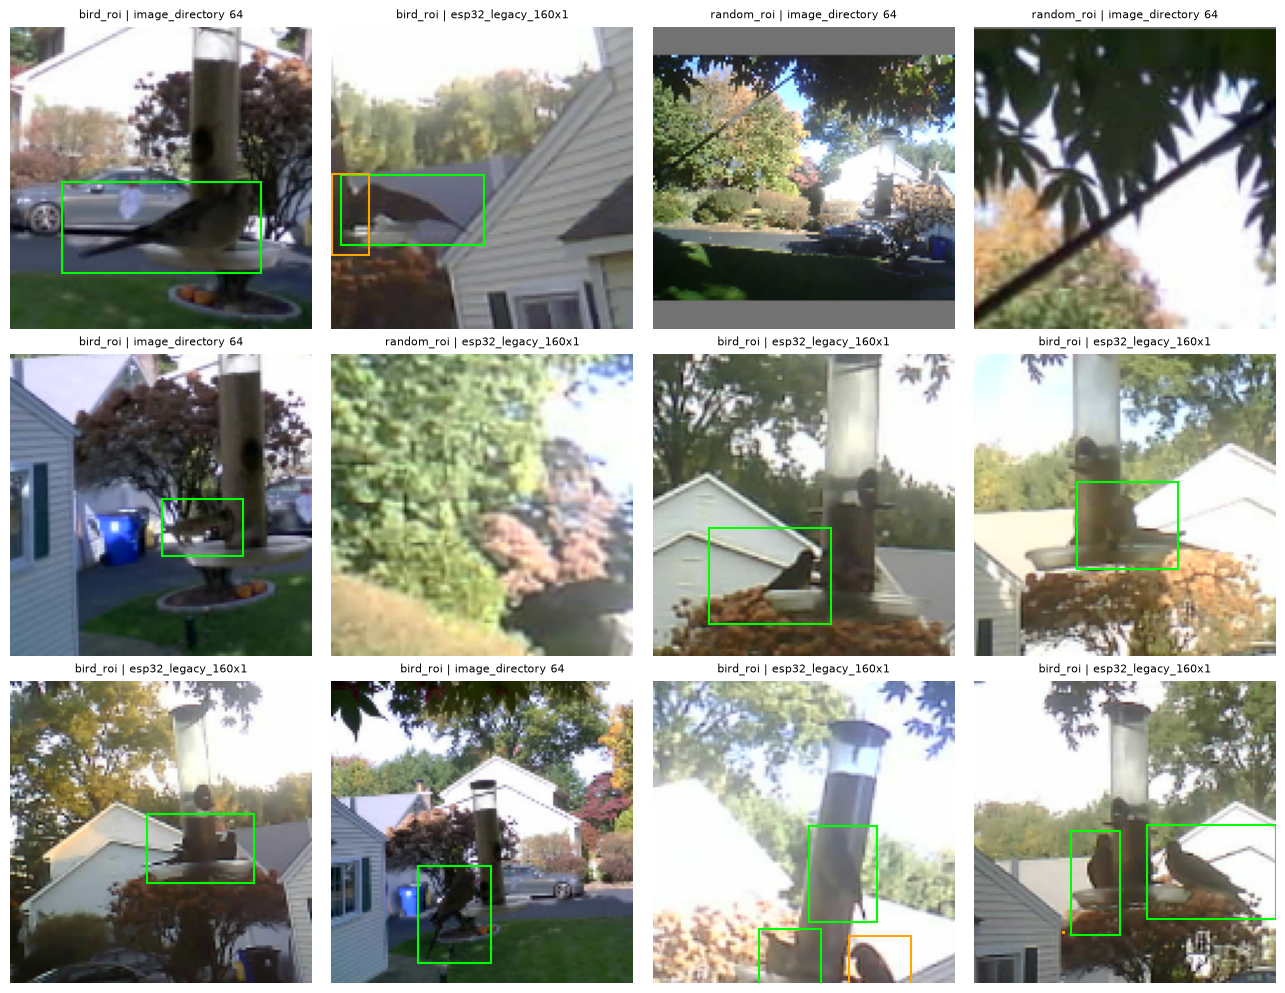

In [6]:
AUTOTUNE = tf.data.AUTOTUNE


def load_roi_tensor(path, crop_box, flip):
    image = tf.cast(tf.io.decode_jpeg(tf.io.read_file(path), channels=3), tf.float32)
    out = tf.image.crop_and_resize(image[None], crop_box[None], [0], [INPUT_SIZE, INPUT_SIZE],
                                   method="bilinear", extrapolation_value=float(PAD_VALUE))[0]
    out = tf.cond(flip, lambda: tf.image.flip_left_right(out), lambda: out)
    return tf.ensure_shape(out, (INPUT_SIZE, INPUT_SIZE, 3))


def augment(image):
    if AUGMENT_COLOR:
        image = tf.image.random_brightness(image, 20.0)
        image = tf.image.random_contrast(image, 0.8, 1.2)
        image = tf.image.random_saturation(image, 0.7, 1.3)
        # occasional greyscale: legacy captures and dusk frames
        grey = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(image))
        image = tf.where(tf.random.uniform([]) < 0.1, grey, image)
    return tf.clip_by_value(image, 0.0, 255.0)


def train_generator():
    rng = np.random.default_rng(SEED + 1)
    while True:
        record, roi, _, flip, positives, ignores = draw_sample(rng)
        yield (record["path"], roi_to_crop_box(roi, record["width"], record["height"]), flip,
               encode_targets(positives, ignores, ANCHORS))


signature = (
    tf.TensorSpec((), tf.string), tf.TensorSpec((4,), tf.float32), tf.TensorSpec((), tf.bool),
    tf.TensorSpec((GRID, GRID, NUM_ANCHORS, 6), tf.float32),
)
train_ds = (
    tf.data.Dataset.from_generator(train_generator, output_signature=signature)
    .map(lambda p, b, f, t: (augment(load_roi_tensor(p, b, f)), t), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(AUTOTUNE)
)


def eval_dataset(items):
    paths = [i["record"]["path"] for i in items]
    boxes = np.stack([roi_to_crop_box(i["roi"], i["record"]["width"], i["record"]["height"]) for i in items])
    targets = np.stack([encode_targets(i["positives"], i["ignores"], ANCHORS) for i in items])
    ds = tf.data.Dataset.from_tensor_slices((paths, boxes, targets))
    ds = ds.map(lambda p, b, t: (load_roi_tensor(p, b, tf.constant(False)), t), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


val_ds = eval_dataset(val_rois)

# Preview: simulated ROIs with their positive (green) and ignore (orange) targets.
preview_rng = np.random.default_rng(SEED + 99)
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax in axes.flat:
    record, roi, mode, flip, positives, ignores = draw_sample(preview_rng)
    image = load_roi_tensor(record["path"], roi_to_crop_box(roi, record["width"], record["height"]), flip).numpy()
    ax.imshow(image.astype(np.uint8))
    for boxes, colour in ((positives, "lime"), (ignores, "orange")):
        for b in boxes * INPUT_SIZE:
            ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color=colour, lw=1.5))
    ax.set_title(f"{mode} | {record['source'][:18]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()

## 7. Model and loss

In [7]:
def build_models():
    inputs = keras.Input((INPUT_SIZE, INPUT_SIZE, 3), name="image")
    x = keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name="scale_to_mobilenet")(inputs)
    backbone = keras.applications.MobileNetV2(
        input_shape=(INPUT_SIZE, INPUT_SIZE, 3), alpha=BACKBONE_ALPHA, include_top=False, weights=WEIGHTS)
    features = keras.Model(backbone.input, backbone.get_layer(FEATURE_LAYER).output, name="backbone")
    if WEIGHTS is None:
        # MobileNetV2's BN momentum (0.999) assumes pretrained statistics; from scratch
        # the moving averages would lag thousands of steps behind and break validation.
        for layer in features.layers:
            if isinstance(layer, keras.layers.BatchNormalization):
                layer.momentum = 0.9
    f = features(x)
    h = keras.layers.SeparableConv2D(HEAD_CHANNELS, 3, padding="same", use_bias=False, name="head_sep")(f)
    h = keras.layers.BatchNormalization(name="head_bn")(h)
    h = keras.layers.ReLU(6.0, name="head_relu")(h)
    box = keras.layers.Conv2D(NUM_ANCHORS * 4, 1, name="box")(h)
    score = keras.layers.Conv2D(NUM_ANCHORS, 1, name="score",
                                bias_initializer=keras.initializers.Constant(-4.6))(h)  # prior ~1%
    deploy = keras.Model(inputs, [box, score], name="esp32_bird_detector")
    packed = keras.layers.Concatenate(axis=-1, name="packed")([
        keras.layers.Reshape((GRID, GRID, NUM_ANCHORS, 4))(box),
        keras.layers.Reshape((GRID, GRID, NUM_ANCHORS, 1))(score),
    ])
    train = keras.Model(inputs, packed, name="esp32_bird_detector_train")
    return deploy, train, features


def detector_loss(y_true, y_pred):
    obj, ignore = y_true[..., 4], y_true[..., 5]
    logits = y_pred[..., 4]
    prob = tf.sigmoid(logits)
    bce = tf.nn.sigmoid_cross_entropy_with_logits(labels=obj, logits=logits)
    p_t = obj * prob + (1 - obj) * (1 - prob)
    alpha_t = obj * FOCAL_ALPHA + (1 - obj) * (1 - FOCAL_ALPHA)
    focal = alpha_t * tf.pow(1 - p_t, FOCAL_GAMMA) * bce
    score_mask = obj + (1 - obj) * (1 - ignore)
    n_pos = tf.maximum(tf.reduce_sum(obj), 1.0)
    score_loss = tf.reduce_sum(focal * score_mask) / n_pos
    t_xy = y_true[..., 0:2]
    xy_entropy = -(t_xy * tf.math.log(tf.clip_by_value(t_xy, 1e-6, 1.0))
                   + (1 - t_xy) * tf.math.log(tf.clip_by_value(1 - t_xy, 1e-6, 1.0)))
    # minus the target entropy: same gradients, but the loss reaches 0 at a perfect box
    xy = tf.reduce_sum(obj[..., None] * (tf.nn.sigmoid_cross_entropy_with_logits(labels=t_xy, logits=y_pred[..., 0:2]) - xy_entropy), -1)
    err = tf.abs(y_true[..., 2:4] - y_pred[..., 2:4])
    wh = tf.reduce_sum(tf.where(err < 1.0, 0.5 * tf.square(err), err - 0.5), -1)  # Huber, delta 1
    box_loss = tf.reduce_sum(obj * (xy + wh)) / n_pos
    return score_loss + BOX_LOSS_WEIGHT * box_loss


deploy_model, train_model, backbone_model = build_models()
deploy_model.summary()


def count_macs(model):
    macs = 0
    stack = list(model.layers)
    while stack:
        layer = stack.pop()
        if isinstance(layer, keras.Model):
            stack.extend(layer.layers)
            continue
        if not hasattr(layer, "kernel_size"):
            continue
        out_h, out_w = layer.output.shape[1], layer.output.shape[2]
        k = int(np.prod(layer.kernel_size))
        in_c = layer.input.shape[-1]
        if isinstance(layer, keras.layers.DepthwiseConv2D):
            macs += out_h * out_w * k * in_c * layer.depth_multiplier
        elif isinstance(layer, keras.layers.SeparableConv2D):
            macs += out_h * out_w * k * in_c + out_h * out_w * in_c * layer.filters
        elif isinstance(layer, keras.layers.Conv2D):
            macs += out_h * out_w * k * in_c * layer.filters
    return int(macs)


MODEL_MACS = count_macs(deploy_model)
print(f"Detector compute: {MODEL_MACS / 1e6:.1f} M MACs per inference "
      f"({deploy_model.count_params():,} parameters)")

Model: "esp32_bird_detector"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 128, 128,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_to_mobilenet  │ (None, 128, 128,  │          0 │ image[0][0]       │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ backbone            │ (None, 8, 8, 192) │     98,512 │ scale_to_mobilen… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_sep            │ (None, 8, 8, 64)  │     14,016 │ backbone[0][0]    │
│ (SeparableConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_bn             │ (None, 8, 8, 64)  │        256 │ head_sep[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_relu (ReLU)    │ (None, 8, 8, 64)  │          0 │ head_bn[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ box (Conv2D)        │ (None, 8, 8, 12)  │        780 │ head_relu[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ score (Conv2D)      │ (None, 8, 8, 3)   │        195 │ head_relu[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 113,759 (444.37 KB)

 Trainable params: 107,087 (418.31 KB)

 Non-trainable params: 6,672 (26.06 KB)

Detector compute: 15.2 M MACs per inference (113,759 parameters)


## 8. Train: head warm-up, then full fine-tune

Run directory: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v2_128_20261102T225645Z
Epoch 1/6


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793660205.626079   62607 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793660208.456502   62687 service.cc:153] XLA service 0x70047c035050 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793660208.456568   62687 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793660208.608534   62687 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1

  3/500 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step - loss: 2.8391   

I0000 00:00:1793660216.947672   62687 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 0.5854
Epoch 1: val_loss improved from None to 0.89030, saving model to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v2_128_20261102T225645Z/head_best.weights.h5

Epoch 1: finished saving model to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v2_128_20261102T225645Z/head_best.weights.h5
500/500 ━━━━━━━━━━━━━━━━━━━━ 55s 87ms/step - loss: 0.5854 - val_loss: 0.8903 - learning_rate: 0.0020
Epoch 2/6
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.4199
Epoch 2: val_loss did not improve from 0.89030
500/500 ━━━━━━━━━━━━━━━━━━━━ 33s 66ms/step - loss: 0.4199 - val_loss: 1.2274 - learning_rate: 0.0020
Epoch 3/6
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 0.3941
Epoch 3: val_loss did not improve from 0.89030
500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 79ms/step - loss: 0.3941 - val_loss: 1.0783 - learning_rate: 0.0020
Ep

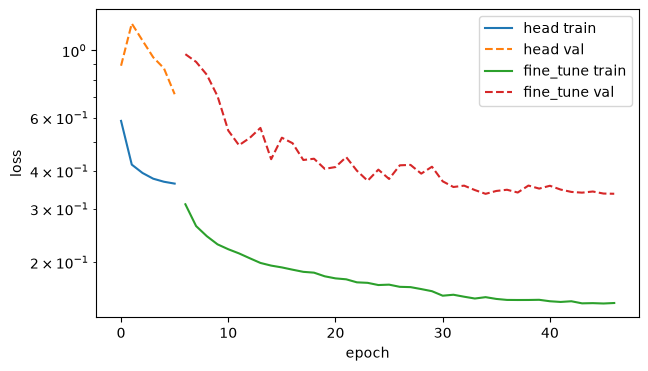

In [8]:
created_utc = datetime.now(timezone.utc)
RUN_NAME = f"esp32_roi_detector_v2_{INPUT_SIZE}_{created_utc:%Y%m%dT%H%M%SZ}"
RUN_DIR = portable_path(OUTPUT_ROOT) / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Run directory:", RUN_DIR)


def callbacks(stage):
    return [
        keras.callbacks.ModelCheckpoint(str(RUN_DIR / f"{stage}_best.weights.h5"), monitor="val_loss",
                                        save_best_only=True, save_weights_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=EARLY_STOP_PATIENCE, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                          patience=max(1, EARLY_STOP_PATIENCE // 2), min_lr=1e-6, verbose=1),
        keras.callbacks.CSVLogger(str(RUN_DIR / f"{stage}_history.csv")),
        keras.callbacks.TerminateOnNaN(),
    ]


started = time.perf_counter()
histories = {}
if WEIGHTS is not None and HEAD_EPOCHS > 0:
    # A frozen *random* backbone has meaningless BatchNorm statistics, so the
    # head-only warm-up only makes sense with pretrained weights.
    backbone_model.trainable = False
    train_model.compile(optimizer=keras.optimizers.Adam(HEAD_LR), loss=detector_loss)
    histories["head"] = train_model.fit(train_ds, steps_per_epoch=STEPS_PER_EPOCH, epochs=HEAD_EPOCHS,
                                        validation_data=val_ds, callbacks=callbacks("head"))
    train_model.load_weights(str(RUN_DIR / "head_best.weights.h5"))

if FINE_TUNE_EPOCHS > 0:
    backbone_model.trainable = True
    train_model.compile(optimizer=keras.optimizers.Adam(FINE_TUNE_LR), loss=detector_loss)
    histories["fine_tune"] = train_model.fit(train_ds, steps_per_epoch=STEPS_PER_EPOCH, epochs=FINE_TUNE_EPOCHS,
                                             validation_data=val_ds, callbacks=callbacks("fine_tune"))
best = {stage: min(h.history["val_loss"]) for stage, h in histories.items()}
train_model.load_weights(str(RUN_DIR / f"{min(best, key=best.get)}_best.weights.h5"))
print("best val_loss per stage:", best)
TRAIN_MINUTES = (time.perf_counter() - started) / 60
print(f"training time {TRAIN_MINUTES:.1f} min")

fig, ax = plt.subplots(figsize=(7, 4))
offset = 0
for stage, history in histories.items():
    n = len(history.history["loss"])
    ax.plot(range(offset, offset + n), history.history["loss"], label=f"{stage} train")
    ax.plot(range(offset, offset + n), history.history["val_loss"], "--", label=f"{stage} val")
    offset += n
ax.set(xlabel="epoch", ylabel="loss", yscale="log")
ax.legend()
plt.savefig(RUN_DIR / "training_loss.png", dpi=140, bbox_inches="tight")

## 9. Export float32 and full-integer TFLite

Input is **uint8 RGB** with the `[0, 255] → [−1, 1]` scaling inside the graph, so the firmware copies resampled bytes straight into the input tensor. Outputs are int8; dequantize with each tensor's `(scale, zero_point)`.

In [9]:
FLOAT_PATH = RUN_DIR / "esp32_detector_float32.tflite"
INT8_PATH = RUN_DIR / "esp32_detector_int8.tflite"
deploy_model.save(RUN_DIR / "esp32_detector.keras")
FLOAT_PATH.write_bytes(tf.lite.TFLiteConverter.from_keras_model(deploy_model).convert())


def representative_dataset():
    rng = np.random.default_rng(SEED + 21)
    for _ in range(REPRESENTATIVE_SAMPLES):
        record, roi, _, flip, _, _ = draw_sample(rng)
        image = load_roi_tensor(record["path"], roi_to_crop_box(roi, record["width"], record["height"]), flip)
        yield [image[None].numpy().astype(np.float32)]


converter = tf.lite.TFLiteConverter.from_keras_model(deploy_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.int8
INT8_PATH.write_bytes(converter.convert())

for path in (FLOAT_PATH, INT8_PATH):
    print(f"{path.name}: {path.stat().st_size / 1024:.1f} KiB")

# Ops the firmware's MicroMutableOpResolver must register.
probe = tf.lite.Interpreter(  # no XNNPACK, so the op list is the real graph
    model_path=str(INT8_PATH),
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
probe.allocate_tensors()
TFLITE_OPS = sorted({op["op_name"] for op in probe._get_ops_details()})
RESOLVER_NAMES = {
    "CONV_2D": "AddConv2D", "DEPTHWISE_CONV_2D": "AddDepthwiseConv2D", "ADD": "AddAdd", "PAD": "AddPad",
    "QUANTIZE": "AddQuantize", "DEQUANTIZE": "AddDequantize", "MUL": "AddMul", "RELU6": "AddRelu6",
    "RESHAPE": "AddReshape", "CONCATENATION": "AddConcatenation", "SUB": "AddSub", "MEAN": "AddMean",
}
print("TFLite ops:", TFLITE_OPS)
print("Resolver:  ", " ".join(f"resolver.{RESOLVER_NAMES.get(op, '<unmapped ' + op + '>')}();" for op in TFLITE_OPS))
print(f"MicroMutableOpResolver<{len(TFLITE_OPS)}> resolver;")

INFO:tensorflow:Assets written to: /tmp/tmpy1zk_twb/assets


INFO:tensorflow:Assets written to: /tmp/tmpy1zk_twb/assets


Saved artifact at '/tmp/tmpy1zk_twb'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='image')
Output Type:
  List[TensorSpec(shape=(None, 8, 8, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 8, 8, 3), dtype=tf.float32, name=None)]
Captures:
  123166246506128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246508816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246506896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246509008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246509392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246509584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246510544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246507280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246507472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12316624651035

W0000 00:00:1793662005.791258   62607 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793662005.791310   62607 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793662005.792059   62607 reader.cc:83] Reading SavedModel from: /tmp/tmpy1zk_twb
I0000 00:00:1793662005.798975   62607 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793662005.798996   62607 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpy1zk_twb
I0000 00:00:1793662005.860552   62607 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793662005.869186   62607 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793662006.249216   62607 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpy1zk_twb
I0000 00:00:1793662006.331393   62607 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 539345 microseconds.


INFO:tensorflow:Assets written to: /tmp/tmpb4bxz2q2/assets


INFO:tensorflow:Assets written to: /tmp/tmpb4bxz2q2/assets


Saved artifact at '/tmp/tmpb4bxz2q2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='image')
Output Type:
  List[TensorSpec(shape=(None, 8, 8, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 8, 8, 3), dtype=tf.float32, name=None)]
Captures:
  123166246506128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246508816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246506896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246509008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246509392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246509584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246510544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246507280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123166246507472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12316624651035

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793662011.395038   62607 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793662011.395144   62607 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793662011.395436   62607 reader.cc:83] Reading SavedModel from: /tmp/tmpb4bxz2q2
I0000 00:00:1793662011.407921   62607 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793662011.407946   62607 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpb4bxz2q2
I0000 00:00:1793662011.469210   62607 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793662011.829153   62607 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpb4bxz2q2
I0000 00:00:1793662011.910432   62607 loader.cc:471] SavedModel load for ta

esp32_detector_float32.tflite: 449.8 KiB
esp32_detector_int8.tflite: 242.7 KiB
TFLite ops: ['ADD', 'CONV_2D', 'DEPTHWISE_CONV_2D', 'MUL', 'QUANTIZE']
Resolver:   resolver.AddAdd(); resolver.AddConv2D(); resolver.AddDepthwiseConv2D(); resolver.AddMul(); resolver.AddQuantize();
MicroMutableOpResolver<5> resolver;


fully_quantize: 0, inference_type: 6, input_inference_type: UINT8, output_inference_type: INT8
W0000 00:00:1793662026.452021   62607 flatbuffer_export.cc:3851] Skipping runtime version metadata in the model. This will be generated by the exporter.
/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 10. Decode, run, and evaluate on fixed validation ROIs

The threshold is tuned on motion ROIs only (`THRESHOLD_MODES`), maximising crop recall subject to `MAX_FALSE_TRIGGER_RATE`: a false trigger just costs one crop that the Pi's isBird rejects, a miss loses the bird. Whole-frame ROIs are reported but not tuned on; the firmware uses them only when no motion box is available.

The metric that matters downstream is **crop recall**: did the best-scoring detection's Pi crop (box + `PI_CROP_CONTEXT`) contain at least `CROP_COVERAGE_MIN` of a real bird? IoU recall is reported too. On negative ROIs (no bird, no ignore area) any detection above threshold is a false trigger that would send a crop to the Pi.

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


int8 tensors: {'input': [[1.0, 0.0], 'uint8'], 'box': [[0.02180430106818676, 0.0], 'int8', 'StatefulPartitionedCall_1:0'], 'score': [[0.06912269443273544, 29.0], 'int8', 'StatefulPartitionedCall_1:1'], 'host_ms_per_roi': 0.5590777835386163}
mean per-ROI max |score_float - score_int8| = 0.0775
Deployment score threshold (int8, validation): 0.2


,threshold,bird_rois,negative_rois,crop_recall,iou_recall,false_trigger_rate
0,0.2,1410,760,0.81773,0.87234,0.068421


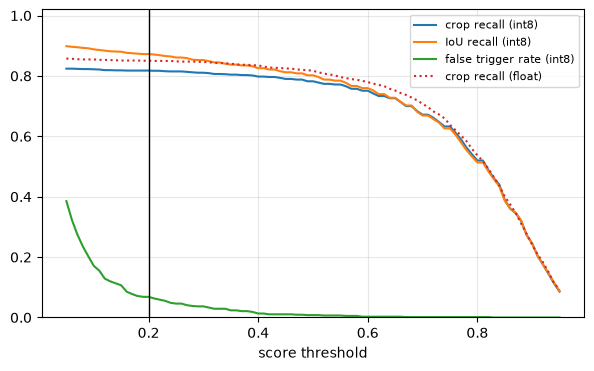

In [10]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


GY, GX = np.meshgrid(np.arange(GRID), np.arange(GRID), indexing="ij")


def decode(box_raw, score_raw, threshold=CANDIDATE_SCORE_THRESHOLD):
    """Raw float outputs (G, G, A*4) and (G, G, A) -> boxes (N, 4) normalized xyxy, scores (N,)."""
    b = box_raw.reshape(GRID, GRID, NUM_ANCHORS, 4)
    s = sigmoid(score_raw.reshape(GRID, GRID, NUM_ANCHORS))
    cx = (sigmoid(b[..., 0]) * 3 - 1 + GX[..., None]) / GRID
    cy = (sigmoid(b[..., 1]) * 3 - 1 + GY[..., None]) / GRID
    w = ANCHORS[:, 0] * np.exp(np.clip(b[..., 2], -4, 4))
    h = ANCHORS[:, 1] * np.exp(np.clip(b[..., 3], -4, 4))
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1).reshape(-1, 4)
    scores = s.reshape(-1)
    keep = scores >= threshold
    boxes, scores = np.clip(boxes[keep], 0, 1), scores[keep]
    order = np.argsort(-scores)
    chosen = []
    while order.size and len(chosen) < MAX_DETECTIONS:
        i = order[0]
        chosen.append(i)
        order = order[1:][iou_one_to_many(boxes[i], boxes[order[1:]]) < NMS_IOU]
    return boxes[chosen], scores[chosen]


def iou_one_to_many(box, boxes):
    if len(boxes) == 0:
        return np.zeros(0)
    ix = np.clip(np.minimum(box[2], boxes[:, 2]) - np.maximum(box[0], boxes[:, 0]), 0, None)
    iy = np.clip(np.minimum(box[3], boxes[:, 3]) - np.maximum(box[1], boxes[:, 1]), 0, None)
    inter = ix * iy
    area = lambda bb: (bb[..., 2] - bb[..., 0]) * (bb[..., 3] - bb[..., 1])
    return inter / np.maximum(area(box) + area(boxes) - inter, 1e-9)


def crop_coverage(det_norm, gt_norm):
    """Share of each GT box inside the context-expanded crop of det (ROI-normalized coords)."""
    w, h = det_norm[2] - det_norm[0], det_norm[3] - det_norm[1]
    crop = np.array([det_norm[0] - PI_CROP_CONTEXT * w, det_norm[1] - PI_CROP_CONTEXT * h,
                     det_norm[2] + PI_CROP_CONTEXT * w, det_norm[3] + PI_CROP_CONTEXT * h])
    ix = np.clip(np.minimum(crop[2], gt_norm[:, 2]) - np.maximum(crop[0], gt_norm[:, 0]), 0, None)
    iy = np.clip(np.minimum(crop[3], gt_norm[:, 3]) - np.maximum(crop[1], gt_norm[:, 1]), 0, None)
    return ix * iy / np.maximum((gt_norm[:, 2] - gt_norm[:, 0]) * (gt_norm[:, 3] - gt_norm[:, 1]), 1e-9)


def limit(items):
    if TFLITE_EVAL_LIMIT is None or len(items) <= TFLITE_EVAL_LIMIT:
        return items
    rng = np.random.default_rng(SEED + 5)
    return [items[i] for i in sorted(rng.choice(len(items), TFLITE_EVAL_LIMIT, replace=False))]


def roi_image(item):
    r = item["record"]
    return load_roi_tensor(r["path"], roi_to_crop_box(item["roi"], r["width"], r["height"]), tf.constant(False)).numpy()


def run_tflite(model_path, items):
    interpreter = tf.lite.Interpreter(model_path=str(model_path), num_threads=4)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    outs = {d["name"]: d for d in interpreter.get_output_details()}
    # Identify box/score outputs by channel count, never by order.
    box_d = next(d for d in outs.values() if d["shape"][-1] == NUM_ANCHORS * 4)
    score_d = next(d for d in outs.values() if d["shape"][-1] == NUM_ANCHORS)

    def deq(detail):
        raw = interpreter.get_tensor(detail["index"])[0]
        scale, zero = detail["quantization"]
        return raw.astype(np.float32) if scale == 0 else (raw.astype(np.float32) - zero) * scale

    results, seconds = [], 0.0
    for item in items:
        x = roi_image(item)[None]
        if inp["dtype"] == np.uint8:
            scale, zero = inp["quantization"]
            x = np.clip(np.rint(x / scale + zero), 0, 255).astype(np.uint8)
        interpreter.set_tensor(inp["index"], x.astype(inp["dtype"]))
        t0 = time.perf_counter()
        interpreter.invoke()
        seconds += time.perf_counter() - t0
        results.append((deq(box_d), deq(score_d)))
    details = {"input": [list(map(float, inp["quantization"])), np.dtype(inp["dtype"]).name],
               "box": [list(map(float, box_d["quantization"])), np.dtype(box_d["dtype"]).name, box_d["name"]],
               "score": [list(map(float, score_d["quantization"])), np.dtype(score_d["dtype"]).name, score_d["name"]],
               "host_ms_per_roi": 1000 * seconds / max(1, len(items))}
    return results, details


def roi_outcomes(items, raw_outputs):
    """Per ROI: best detection score for crop recall / IoU recall, and max score for false triggers."""
    rows = []
    for item, (box_raw, score_raw) in zip(items, raw_outputs):
        boxes, scores = decode(box_raw, score_raw)
        gt = item["positives"]
        row = {"mode": item["mode"], "source": item["record"]["source"], "has_bird": len(gt) > 0,
               "negative": len(gt) == 0 and len(item["ignores"]) == 0,
               "max_score": float(scores.max()) if len(scores) else 0.0,
               "crop_hit_score": 0.0, "iou_hit_score": 0.0}
        if len(gt) and len(boxes):
            # The firmware sends one crop: the top detection. Score it as such.
            top = boxes[0]
            if (crop_coverage(top, gt) >= CROP_COVERAGE_MIN).any():
                row["crop_hit_score"] = float(scores[0])
            ious = np.array([iou_one_to_many(b, gt).max() for b in boxes])
            hits = scores[ious >= IOU_MATCH]
            row["iou_hit_score"] = float(hits.max()) if len(hits) else 0.0
        rows.append(row)
    return pd.DataFrame(rows)


def metrics_at(outcomes, threshold):
    birds, negatives = outcomes[outcomes["has_bird"]], outcomes[outcomes["negative"]]
    return {
        "threshold": float(threshold),
        "bird_rois": len(birds), "negative_rois": len(negatives),
        "crop_recall": float((birds["crop_hit_score"] >= threshold).mean()) if len(birds) else np.nan,
        "iou_recall": float((birds["iou_hit_score"] >= threshold).mean()) if len(birds) else np.nan,
        "false_trigger_rate": float((negatives["max_score"] >= threshold).mean()) if len(negatives) else np.nan,
    }


val_eval = limit(val_rois)
val_raw_float, float_details = run_tflite(FLOAT_PATH, val_eval)
val_raw_int8, int8_details = run_tflite(INT8_PATH, val_eval)
val_float = roi_outcomes(val_eval, val_raw_float)
val_int8 = roi_outcomes(val_eval, val_raw_int8)
print("int8 tensors:", int8_details)
drift = np.mean([np.abs(sigmoid(a[1]) - sigmoid(b[1])).max() for a, b in zip(val_raw_float, val_raw_int8)])
print(f"mean per-ROI max |score_float - score_int8| = {drift:.4f}")

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
tune_int8 = val_int8[val_int8["mode"].isin(THRESHOLD_MODES)]
sweep = pd.DataFrame([metrics_at(tune_int8, t) for t in thresholds])
sweep_float = pd.DataFrame([metrics_at(val_float[val_float["mode"].isin(THRESHOLD_MODES)], t) for t in thresholds])
sweep.to_csv(RUN_DIR / "validation_threshold_sweep_int8.csv", index=False)
ok = sweep[sweep["false_trigger_rate"] <= MAX_FALSE_TRIGGER_RATE]
if ok.empty:
    print(f"warning: no threshold keeps false triggers <= {MAX_FALSE_TRIGGER_RATE}; using the highest swept threshold")
    DEPLOY_THRESHOLD = float(thresholds[-1])
else:
    # best recall; among ties the higher threshold (fewer wasted crops)
    DEPLOY_THRESHOLD = float(ok.sort_values(["crop_recall", "threshold"], ascending=[False, False]).iloc[0]["threshold"])
print("Deployment score threshold (int8, validation):", DEPLOY_THRESHOLD)
display(pd.DataFrame([metrics_at(tune_int8, DEPLOY_THRESHOLD)]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep["threshold"], sweep["crop_recall"], label="crop recall (int8)")
ax.plot(sweep["threshold"], sweep["iou_recall"], label="IoU recall (int8)")
ax.plot(sweep["threshold"], sweep["false_trigger_rate"], label="false trigger rate (int8)")
ax.plot(sweep_float["threshold"], sweep_float["crop_recall"], ":", label="crop recall (float)")
ax.axvline(DEPLOY_THRESHOLD, color="k", lw=1)
ax.set(xlabel="score threshold", ylim=(0, 1.02))
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.savefig(RUN_DIR / "validation_sweep.png", dpi=140, bbox_inches="tight")

## 11. Test once, with per-mode and per-source breakdown

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,split,slice,threshold,bird_rois,negative_rois,crop_recall,iou_recall,false_trigger_rate
0,validation,motion ROIs (tuned),0.2,1410,760,0.817730,0.872340,0.068421
1,validation,all,0.2,2433,994,0.743938,0.796547,0.163984
2,validation,bird_roi / esp32_legacy_160x120 160x120,0.2,103,0,0.912621,0.941748,NaN
3,validation,bird_roi / esp32_legacy_160x120 640x480,0.2,636,0,0.864780,0.915094,NaN
4,validation,bird_roi / image_directory 640x480,0.2,303,0,0.861386,0.933993,NaN
5,validation,random_roi / esp32_legacy_160x120 160x120,0.2,26,64,0.923077,0.961538,0.062500
6,validation,random_roi / esp32_legacy_160x120 640x480,0.2,237,464,0.738397,0.751055,0.051724
7,validation,random_roi / image_directory 640x480,0.2,105,232,0.466667,0.619048,0.103448
8,validation,whole_frame / esp32_legacy_160x120 160x120,0.2,103,54,0.922330,0.941748,0.037037
9,validation,whole_frame / esp32_legacy_160x120 640x480,0.2,635,124,0.678740,0.688189,0.491935


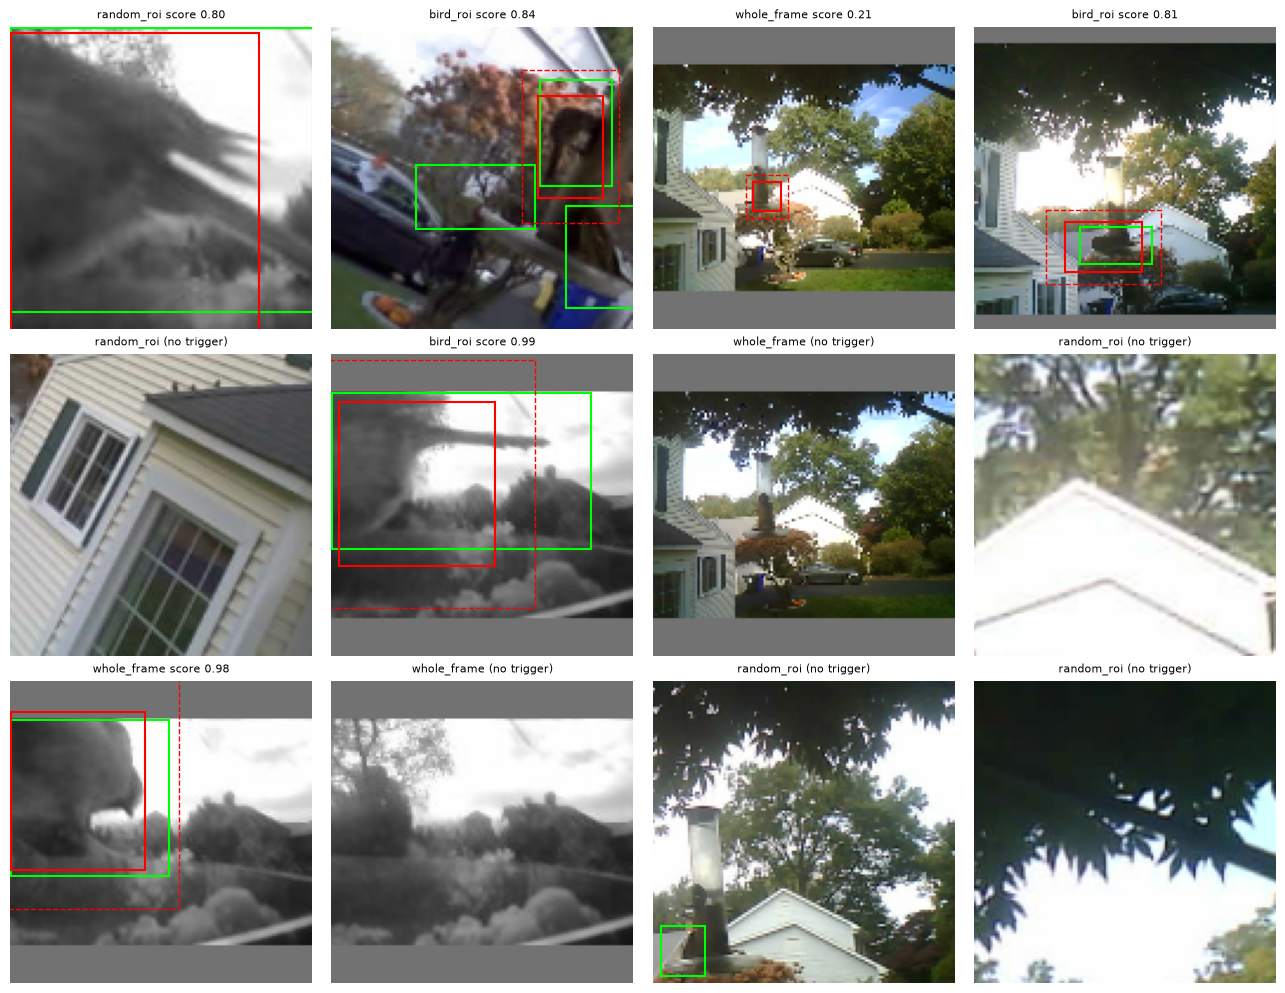

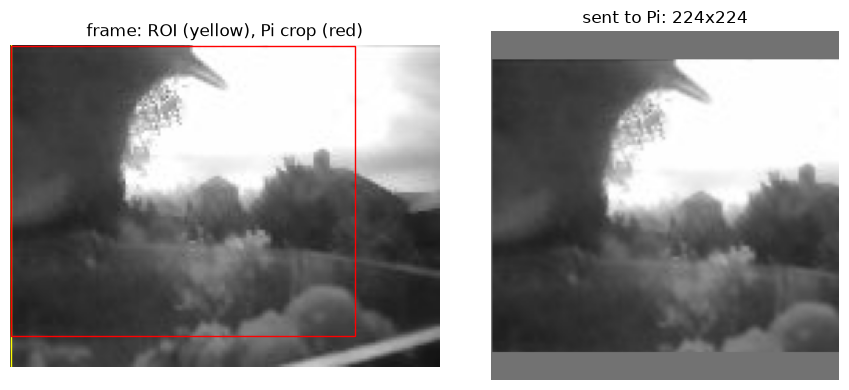

In [11]:
test_eval = limit(test_rois)
test_raw_int8, _ = run_tflite(INT8_PATH, test_eval)
test_int8 = roi_outcomes(test_eval, test_raw_int8)

rows = []
for split, outcomes in (("validation", val_int8), ("test", test_int8)):
    rows.append({"split": split, "slice": "motion ROIs (tuned)",
                 **metrics_at(outcomes[outcomes["mode"].isin(THRESHOLD_MODES)], DEPLOY_THRESHOLD)})
    rows.append({"split": split, "slice": "all", **metrics_at(outcomes, DEPLOY_THRESHOLD)})
    for (mode, source), part in outcomes.groupby(["mode", "source"]):
        rows.append({"split": split, "slice": f"{mode} / {source}", **metrics_at(part, DEPLOY_THRESHOLD)})
results = pd.DataFrame(rows)
results.to_csv(RUN_DIR / "results_int8.csv", index=False)
display(results)

# Visual check: test ROIs with ground truth (green), top detection (red), and its Pi crop region (dashed).
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
pick = np.random.default_rng(SEED + 3).choice(len(test_eval), size=min(12, len(test_eval)), replace=False)
for ax, i in zip(axes.flat, pick):
    item = test_eval[i]
    ax.imshow(roi_image(item).astype(np.uint8))
    for b in item["positives"] * INPUT_SIZE:
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="lime", lw=1.5))
    boxes, scores = decode(*test_raw_int8[i])
    if len(scores) and scores[0] >= DEPLOY_THRESHOLD:
        b = boxes[0]
        w, h = b[2] - b[0], b[3] - b[1]
        c = np.array([b[0] - PI_CROP_CONTEXT * w, b[1] - PI_CROP_CONTEXT * h, b[2] + PI_CROP_CONTEXT * w, b[3] + PI_CROP_CONTEXT * h]) * INPUT_SIZE
        b = b * INPUT_SIZE
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="red", lw=1.5))
        ax.add_patch(plt.Rectangle((c[0], c[1]), c[2] - c[0], c[3] - c[1], fill=False, color="red", lw=1, ls="--"))
        ax.set_title(f"{item['mode']} score {scores[0]:.2f}", fontsize=8)
    else:
        ax.set_title(f"{item['mode']} (no trigger)", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RUN_DIR / "test_examples.png", dpi=140, bbox_inches="tight")

# End-to-end reference: frame -> ROI -> detection -> what the Pi would receive.
demo = next((item for item in test_eval if len(item["positives"])), test_eval[0])
boxes, scores = decode(*test_raw_int8[test_eval.index(demo)])
if len(scores):
    full = decode_rgb(demo["record"]["path"])
    pi_crop, pi_meta = make_pi_crop(full, roi_box_to_frame(boxes[0], demo["roi"]))
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(full)
    l, t, r, b = demo["roi"]
    axes[0].add_patch(plt.Rectangle((l, t), r - l, b - t, fill=False, color="yellow"))
    cl, ct, cr, cb = pi_meta["crop_px"]
    axes[0].add_patch(plt.Rectangle((cl, ct), cr - cl, cb - ct, fill=False, color="red"))
    axes[0].set_title("frame: ROI (yellow), Pi crop (red)")
    axes[1].imshow(pi_crop)
    axes[1].set_title(f"sent to Pi: {PI_CROP_SIZE}x{PI_CROP_SIZE}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()

## 12. Firmware artifacts and contract

- `esp32_detector_model.h` — the int8 model as a 16-byte-aligned C array (put it in `include/`).
- `esp32_detector_contract.h` — every constant the firmware needs: geometry, anchors, quantization, threshold, op count.
- `esp32_detector_contract.json` — the same contract for the Pi / isBird notebook.

Measure `interpreter.arena_used_bytes()` on the board and set the tensor arena from it; allocate the arena in PSRAM.

In [12]:
int8_bytes = INT8_PATH.read_bytes()
box_q, score_q, in_q = int8_details["box"][0], int8_details["score"][0], int8_details["input"][0]

contract = {
    "schema_version": 1,
    "run_name": RUN_NAME,
    "created_utc": created_utc.isoformat(),
    "model_file": INT8_PATH.name,
    "model_sha256": sha256_file(INT8_PATH),
    "model_bytes": len(int8_bytes),
    "model_macs": MODEL_MACS,
    "tflite_ops": TFLITE_OPS,
    "input": {
        "shape": [1, INPUT_SIZE, INPUT_SIZE, 3], "dtype": "uint8", "color_order": "RGB",
        "quantization": in_q, "numeric_scaling": "[0,255] -> [-1,1] inside the model",
    },
    "outputs": {
        "box": {"shape": [1, GRID, GRID, NUM_ANCHORS * 4], "dtype": "int8", "quantization": box_q,
                "layout": "[gy][gx][anchor][tx,ty,tw,th]", "tensor_name": int8_details["box"][2]},
        "score": {"shape": [1, GRID, GRID, NUM_ANCHORS], "dtype": "int8", "quantization": score_q,
                  "layout": "[gy][gx][anchor] logit", "tensor_name": int8_details["score"][2]},
        "identify_outputs_by": "last dimension (A*4 = box, A = score), not by index",
    },
    "anchors_normalized_wh": ANCHORS,
    "decode": {
        "center_x": "(sigmoid(tx) * 3 - 1 + gx) / G", "center_y": "(sigmoid(ty) * 3 - 1 + gy) / G",
        "width": "anchor_w * exp(clamp(tw, -4, 4))", "height": "anchor_h * exp(clamp(th, -4, 4))",
        "score": "sigmoid(logit)", "coordinates": "normalized to the square ROI",
        "candidate_score_threshold": CANDIDATE_SCORE_THRESHOLD, "nms_iou": NMS_IOU,
        "max_detections": MAX_DETECTIONS, "deployment_score_threshold": DEPLOY_THRESHOLD,
        "deployment_logit_threshold": float(np.log(DEPLOY_THRESHOLD / (1 - DEPLOY_THRESHOLD))),
    },
    "roi": {
        "function": "square_roi", "expand": ROI_EXPAND, "min_side_fraction_of_min_frame_dim": ROI_MIN_SIDE_FRACTION,
        "max_side": "max(frame_w, frame_h)", "rounding": "side, x0, y0 rounded half-away from zero",
        "placement": "slide inside frame if side fits that axis, else centre ((frame - side) // 2)",
    },
    "resample": {
        "method": "bilinear, pixel-centre aligned",
        "formula": "src = start + (dst + 0.5) * extent / out - 0.5",
        "outside_frame": "PAD_VALUE for samples outside [0, W-1] x [0, H-1]", "pad_value": PAD_VALUE,
    },
    "pi_crop": {
        "detection": "top-scoring box only", "context_per_edge": PI_CROP_CONTEXT,
        "rounding": "floor(left, top), ceil(right, bottom), clipped to the frame",
        "output": [PI_CROP_SIZE, PI_CROP_SIZE, 3], "letterbox": "aspect-preserving, centred, (out - new) // 2",
        "pad_value": PAD_VALUE, "resample": "same bilinear formula",
    },
    "threshold_policy": {"modes": list(THRESHOLD_MODES), "max_false_trigger_rate": MAX_FALSE_TRIGGER_RATE},
    "validation_int8": metrics_at(val_int8[val_int8["mode"].isin(THRESHOLD_MODES)], DEPLOY_THRESHOLD),
    "test_int8": metrics_at(test_int8[test_int8["mode"].isin(THRESHOLD_MODES)], DEPLOY_THRESHOLD),
    "training": {"combined_csv": str(COMBINED_CSV_PATH), "combined_csv_sha256": sha256_file(COMBINED_CSV_PATH),
                 "sample_mix": SAMPLE_MIX, "minutes": TRAIN_MINUTES, "seed": SEED, "quick_run": QUICK_RUN},
}
(RUN_DIR / "esp32_detector_contract.json").write_text(json.dumps(json_safe(contract), indent=2), encoding="utf-8")
(RUN_DIR / "anchors.json").write_text(json.dumps(ANCHORS.tolist()), encoding="utf-8")

hex_lines = [", ".join(f"0x{b:02x}" for b in int8_bytes[i:i + 16]) for i in range(0, len(int8_bytes), 16)]
(RUN_DIR / "esp32_detector_model.h").write_text(
    "// Generated by train_esp32_roi_detector.ipynb - do not edit.\n"
    f"// {RUN_NAME}  sha256 {contract['model_sha256']}\n"
    "#pragma once\n#include <stddef.h>\n#include <stdint.h>\n\n"
    "alignas(16) const uint8_t kBirdDetectorModel[] = {\n  " + ",\n  ".join(hex_lines) + "\n};\n"
    f"const size_t kBirdDetectorModelLen = {len(int8_bytes)};\n", encoding="utf-8")

anchor_rows = ",\n  ".join(f"{{{a[0]:.6f}f, {a[1]:.6f}f}}" for a in ANCHORS)
(RUN_DIR / "esp32_detector_contract.h").write_text(f"""// Generated by train_esp32_roi_detector.ipynb - do not edit.
// {RUN_NAME}
#pragma once

constexpr int kDetInputSize = {INPUT_SIZE};
constexpr int kDetGrid = {GRID};
constexpr int kDetAnchors = {NUM_ANCHORS};
constexpr float kDetAnchorsWH[kDetAnchors][2] = {{
  {anchor_rows}
}};
constexpr float kDetBoxScale = {box_q[0]:.9g}f;
constexpr int kDetBoxZeroPoint = {int(box_q[1])};
constexpr float kDetScoreScale = {score_q[0]:.9g}f;
constexpr int kDetScoreZeroPoint = {int(score_q[1])};
constexpr float kDetScoreThreshold = {DEPLOY_THRESHOLD:.4f}f;
constexpr float kDetCandidateThreshold = {CANDIDATE_SCORE_THRESHOLD:.4f}f;
constexpr float kDetNmsIou = {NMS_IOU:.3f}f;
constexpr int kDetMaxDetections = {MAX_DETECTIONS};
constexpr int kDetOpCount = {len(TFLITE_OPS)};  // MicroMutableOpResolver<kDetOpCount>

constexpr float kRoiExpand = {ROI_EXPAND:.4f}f;
constexpr float kRoiMinSideFraction = {ROI_MIN_SIDE_FRACTION:.4f}f;
constexpr int kPadValue = {PAD_VALUE};

constexpr float kPiCropContext = {PI_CROP_CONTEXT:.4f}f;
constexpr int kPiCropSize = {PI_CROP_SIZE};
""", encoding="utf-8")

print("Wrote", RUN_DIR)
for path in sorted(RUN_DIR.iterdir()):
    print(f"  {path.name:42s} {path.stat().st_size / 1024:9.1f} KiB")

Wrote /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v2_128_20261102T225645Z
  anchors.json                                     0.1 KiB
  esp32_detector.keras                           905.1 KiB
  esp32_detector_contract.h                        0.9 KiB
  esp32_detector_contract.json                     3.8 KiB
  esp32_detector_float32.tflite                  449.8 KiB
  esp32_detector_int8.tflite                     242.7 KiB
  esp32_detector_model.h                        1486.9 KiB
  fine_tune_best.weights.h5                     1717.3 KiB
  fine_tune_history.csv                            2.6 KiB
  head_best.weights.h5                           913.7 KiB
  head_history.csv                                 0.4 KiB
  results_int8.csv                                 2.3 KiB
  test_examples.png                              480.2 KiB
  training_loss.png                               45.0 KiB
  validation_sweep.png            